In [2]:
# https://arxiv.org/pdf/2505.16932
import torch
import math
import numpy as np
from matplotlib import pyplot as plt

In [3]:
l=1e-3
u=1
cushion=0.02
# nanochat is safe factor = 1.02, may be instable in bfloat16
safe_factor = 1.03
p_list=[]
l_list=[]
u_list=[]
l_pre_list=[]
u_pre_list=[]
lambda_list=[]
for j in range(5):
    x1=max(cushion*u,l)
    x4=u
    if(u/l<=(1+1e-3)):
        print(f"iteration{j}:converge")
        break
    x=[(i*x4+(3-i)*x1)/3 for i in range(4)]
    x1,x2,x3,x4=x
    e,old_e=math.inf,None
    while not old_e or abs(old_e-e)>1e-6:
        old_e=e
        x=torch.tensor([
            [x1,x1**3,x1**5,-1],
            [x2,x2**3,x2**5,1],
            [x3,x3**3,x3**5,-1],
            [x4,x4**3,x4**5,1]
        ],dtype=torch.float64)
        y=torch.tensor([
            [1.],
            [1.],
            [1.],
            [1.]
        ],dtype=torch.float64)
        p=x.inverse()@y
        a,b,c,e=p.squeeze(-1).tolist()
        x2_=math.sqrt((-3*b-math.sqrt(9*b**2-4*5*c*a))/(10*c))
        x3_=math.sqrt((-3*b+math.sqrt(9*b**2-4*5*c*a))/(10*c))
        x2_step=abs(x2-x2_)
        x3_step=abs(x3-x3_)
        x2=x2_
        x3=x3_
    y_=lambda t,a=a,b=b,c=c:a*t+b*t**3+c*t**5
    if cushion*u>l:
        l_=y_(l)
        u_=y_(u)
        scaler=2/(l_+u_)
        a,b,c=a*scaler,b*scaler,c*scaler
    if j!=4:
        a,b,c=a/safe_factor,b/safe_factor,c/safe_factor
    y=lambda t,a=a,b=b,c=c:a*t+b*t**3+c*t**5
    l_pre_list.append(l)
    u_pre_list.append(u)
    l=y(l)
    # u=y(u)
    u=2-l
    lambda_list.append(y)
    p_list.append([a,b,c])
    l_list.append(l)
    u_list.append(u)
print(p_list)
print(l_list)
print(u_list)


[[8.077364675154751, -23.164514872804553, 17.02082042895468], [4.004175387920777, -2.8941542019134276, 0.5359620057631334], [3.8575603752860568, -2.8573722859634496, 0.5422813720930638], [3.273090811768049, -2.454155567360048, 0.4995156193426476], [2.3739476001512374, -1.733927991006291, 0.42586024687456364]]
[0.0080773415106569, 0.03234156689450751, 0.1246629054009082, 0.4032934515972897, 0.8482057233706921]
[1.991922658489343, 1.9676584331054925, 1.8753370945990917, 1.5967065484027103, 1.151794276629308]


In [4]:
x=0.8216
for i in range(5):
    x=lambda_list[i](x)
    print(x)

0.16138155169443458
0.6340945119380954
1.7731488547092518
0.8774334668133186
1.1331480569168968


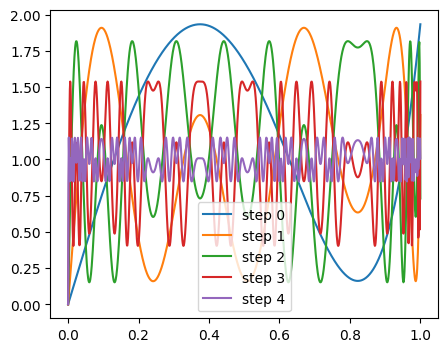

In [5]:
x=np.linspace(0,1,1000)
y=x.copy()
fig,axe=plt.subplots(figsize=(5,4))
for i in range(5):
    y=lambda_list[i](y)
    axe.plot(x,y,label=f'step {i}')
axe.legend()

tensor(1.1562, dtype=torch.bfloat16)

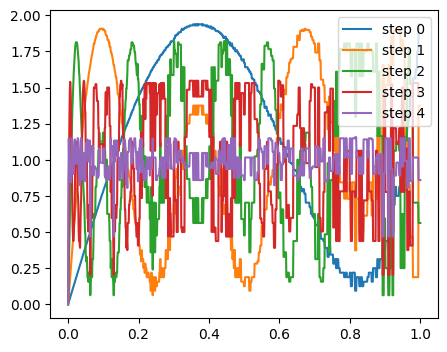

In [6]:
x=np.linspace(0,1,1000)
y=torch.tensor(x,dtype=torch.bfloat16)
fig,axe=plt.subplots(figsize=(5,4))
for i in range(5):
    y=lambda_list[i](y)
    axe.plot(x,y.float().numpy(),label=f'step {i}')
axe.legend()
y.max()

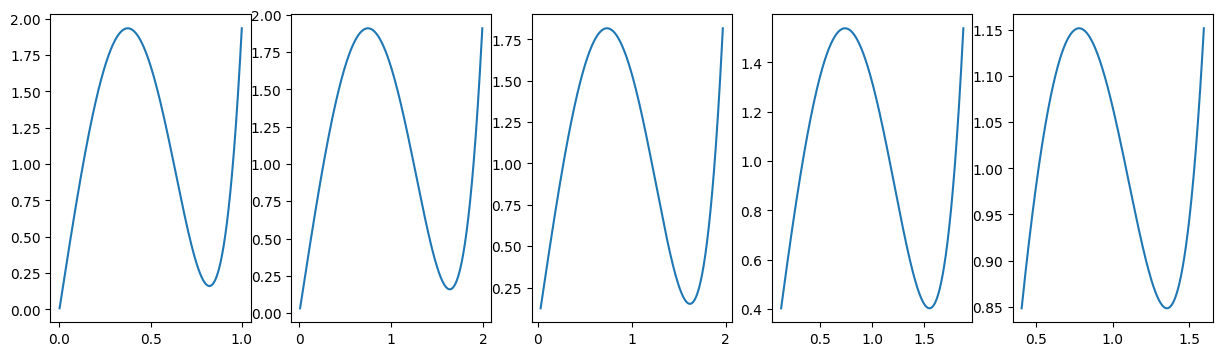

In [7]:
fig,axe=plt.subplots(1,5,figsize=(15,4))
for i in range(5):
    x=np.linspace(l_pre_list[i],u_pre_list[i],1000)
    y=lambda_list[i](x)
    axe[i].plot(x,y,label=f'step {i}')